# Telecom Customer Churn: Cleaning, EDA and Modelling
Assignment 1 (Portfolio), Option A: predicting customer churn for a telecom provider.

In this notebook we load and clean the Telco Customer Churn data (IBM sample data, also on Kaggle by BlastChar; 7,043 customers, 21 columns), explore it, build a few extra features, compare two classifiers (Logistic Regression and Random Forest), and then look at how the final model behaves. The final model is saved as a `.joblib` file. Source details are in `DATASET_SOURCE.md`.

**Sections:** 1 Setup, 2 Cleaning, 3 EDA, 4 Feature engineering, 5 Model training and comparison, 6 Saving the model, 7 Results and evaluation.

Version note: all numbers in this notebook and the report come from one run (library versions are printed in the setup cell). Random Forest results can move slightly in the third decimal on other scikit-learn versions, so load the saved models with the version listed in `models/model_metadata.json`.

## 1. Setup and loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, sys, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn, scipy
from scipy import stats

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1


In [2]:
# Load the data. If the local copy is missing (e.g. in Google Colab), download it from the public IBM mirror.
LOCAL_PATH = "data/Telco-Customer-Churn.csv"
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df_raw = pd.read_csv(LOCAL_PATH if os.path.exists(LOCAL_PATH) else URL)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (7043, 21)


   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

## 2. Data cleaning and validation

### 2.1 First look at the data

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Summary of the numeric columns
df_raw.describe()

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000

In [5]:
# Missing values, duplicates and unique values per column
print("Missing values (NaN):", df_raw.isna().sum().sum())
print("Duplicate rows:", df_raw.duplicated().sum())
print("Duplicate customer IDs:", df_raw["customerID"].duplicated().sum())
print()
print(df_raw.nunique().sort_values())

Missing values (NaN): 0
Duplicate rows: 0
Duplicate customer IDs: 0

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
MultipleLines          3
TechSupport            3
StreamingTV            3
OnlineBackup           3
DeviceProtection       3
StreamingMovies        3
Contract               3
OnlineSecurity         3
InternetService        3
PaymentMethod          4
tenure                73
MonthlyCharges      1585
TotalCharges        6531
customerID          7043
dtype: int64


`TotalCharges` is stored as text, not a number, even though it holds amounts. That usually means some entries are blank strings. Checking next.

In [6]:
# Find the entries that cannot be converted to numbers
blank_mask = pd.to_numeric(df_raw["TotalCharges"], errors="coerce").isna()
print("Rows with a non-numeric TotalCharges:", blank_mask.sum())
df_raw.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows with a non-numeric TotalCharges: 11


      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No

All 11 problem rows have `tenure = 0`, so these are new customers who haven't been billed yet and their total charges really are zero. We convert the column to numeric and fill the 11 blanks with 0. None of the 11 churned, and they are only 0.16% of the data, so this choice has almost no effect. We keep them so we still have all 7,043 customers.

In [7]:
df = df_raw.copy()

# 1. Fix TotalCharges: convert to number, blanks -> 0 (new customers, tenure = 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
assert (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all()
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# 2. SeniorCitizen is 0/1; turn it into Yes/No so all categorical columns look alike
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# 3. 'No internet service' / 'No phone service' just repeat information already held in
#    InternetService / PhoneService, so merge them into 'No'
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
for col in service_cols:
    df[col] = df[col].replace({"No internet service": "No", "No phone service": "No"})

# 4. Target variable: Churn Yes/No -> 1/0
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# 5. customerID is just an identifier with no predictive value; keep it aside and drop it
customer_ids = df.pop("customerID")

print("Missing values after cleaning:", df.isna().sum().sum())
print("Rows identical on every feature (different customers, same profile):", df.duplicated().sum())
df.dtypes

Missing values after cleaning: 0
Rows identical on every feature (different customers, same profile): 22


gender                  str
SeniorCitizen           str
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

Because most columns are categorical, 22 customers have exactly the same profile as another customer. They have different IDs so they are real, separate people and we keep them. Identical profiles could land on both sides of the train/test split and make test scores slightly optimistic, but with 22 rows out of 7,043 the effect is tiny.

### 2.2 Consistency checks (is the data internally coherent?)

In [8]:
# Logical consistency between columns
print("PhoneService = No but MultipleLines is not 'No phone service':",
      ((df_raw["PhoneService"] == "No") & (df_raw["MultipleLines"] != "No phone service")).sum())
print("InternetService = No but an add-on is not 'No internet service':",
      ((df_raw["InternetService"] == "No") & (df_raw["OnlineSecurity"] != "No internet service")).sum())

# TotalCharges should be roughly tenure x MonthlyCharges (prices change over time, so not exact)
billed = df_raw["tenure"] > 0
tc = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")
ratio = tc[billed] / (df_raw.loc[billed, "tenure"] * df_raw.loc[billed, "MonthlyCharges"])
print("\nTotalCharges / (tenure x MonthlyCharges): median = %.2f, 5th-95th percentile = %.2f to %.2f"
      % (ratio.median(), ratio.quantile(0.05), ratio.quantile(0.95)))
print("Customers whose total differs from tenure x monthly by more than 25%%: %d (%.1f%%)"
      % ((abs(ratio - 1) > 0.25).sum(), (abs(ratio - 1) > 0.25).mean() * 100))

PhoneService = No but MultipleLines is not 'No phone service': 0
InternetService = No but an add-on is not 'No internet service': 0

TotalCharges / (tenure x MonthlyCharges): median = 1.00, 5th-95th percentile = 0.92 to 1.07
Customers whose total differs from tenure x monthly by more than 25%: 27 (0.4%)


The columns are consistent with each other: no customer has multiple lines without a phone service, and none has internet add-ons without internet. `TotalCharges` is close to `tenure x MonthlyCharges` for nearly everyone, and the small gaps fit price or plan changes over time, so we trust the billing columns. It also means `TotalCharges` adds little beyond those two columns (see Figure 8).

### 2.3 Outlier check

In [9]:
# IQR rule on the three numeric columns
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:15s} min={df[col].min():8.2f}  max={df[col].max():8.2f}  outliers by IQR rule: {n_out}")

tenure          min=    0.00  max=   72.00  outliers by IQR rule: 0
MonthlyCharges  min=   18.25  max=  118.75  outliers by IQR rule: 0
TotalCharges    min=    0.00  max= 8684.80  outliers by IQR rule: 0


No outliers by the IQR rule, and all values look plausible (tenure 0-72 months, monthly charges about \$18-\$119), so nothing was removed.

### 2.4 Cleaning summary
| Issue | Action |
|---|---|
| `TotalCharges` stored as text, 11 blank values | Converted to numeric, blanks set to 0 (all had tenure = 0) |
| `SeniorCitizen` coded 0/1 | Converted to Yes/No to match the other columns |
| "No internet service" / "No phone service" categories | Merged into "No" (already captured in other columns) |
| `Churn` coded Yes/No | Encoded as 1/0 |
| `customerID` | Dropped (identifier only) |
| Duplicates / outliers | None found; 22 identical-profile rows kept (different customers) |
| Consistency checks | Phone/internet logic and billing totals line up |

## 3. Exploratory data analysis (EDA)

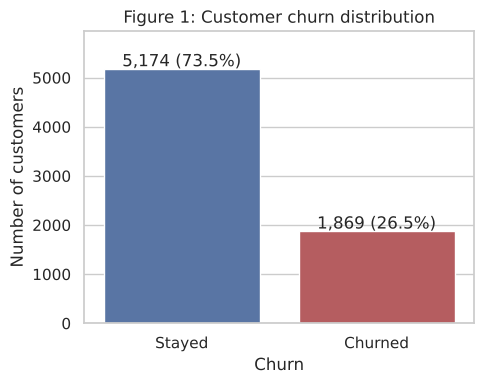

In [10]:
# Figure 1: How many customers churn?
counts = df["Churn"].value_counts().rename({0: "Stayed", 1: "Churned"})
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=counts.index, y=counts.values, palette=["#4C72B0", "#C44E52"], ax=ax)
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, c + 60, f"{c:,} ({p:.1f}%)", ha="center")
ax.set_title("Figure 1: Customer churn distribution")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig("figures/fig1_churn_distribution.png", dpi=150)
plt.show()

About 26.5% of customers churned, so roughly 3 stay for every 1 who leaves. A model that predicts "stays" for everyone would be about 73% accurate and still useless, so we look at recall and F1 as well as accuracy.

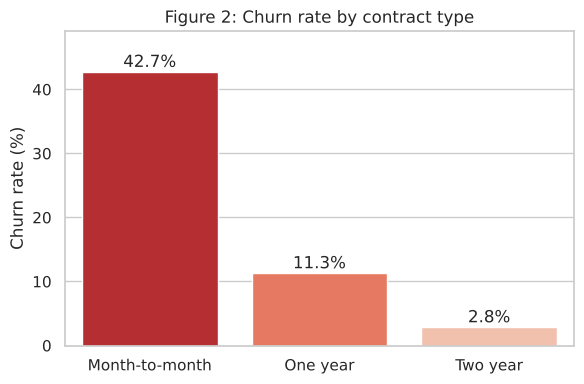

In [11]:
# Figure 2: Churn rate by contract type
rate = df.groupby("Contract")["Churn"].mean().reindex(["Month-to-month", "One year", "Two year"]) * 100

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=rate.index, y=rate.values, palette="Reds_r", ax=ax)
for i, v in enumerate(rate.values):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
ax.set_title("Figure 2: Churn rate by contract type")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("")
ax.set_ylim(0, rate.max() * 1.15)
plt.tight_layout()
plt.savefig("figures/fig2_churn_by_contract.png", dpi=150)
plt.show()

Month-to-month customers churn far more than customers on one- or two-year contracts. This is a strong association, but it doesn't show the contract causes churn: people who plan to leave may just prefer a flexible contract.

         mean  median
Churn                
Stayed   37.6    38.0
Churned  18.0    10.0


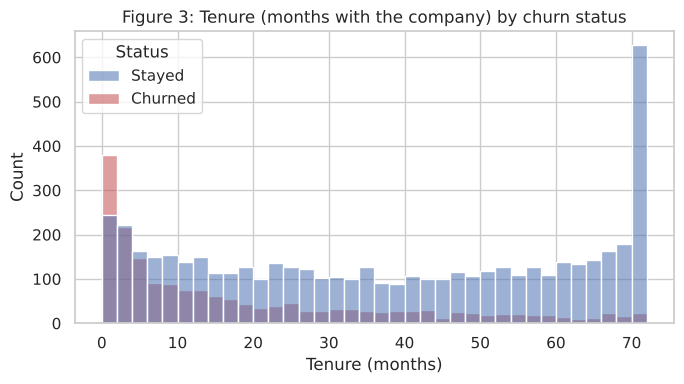

In [12]:
# Figure 3: Tenure distribution for churners vs stayers
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=df.assign(Status=df["Churn"].map({0: "Stayed", 1: "Churned"})),
             x="tenure", hue="Status", bins=36, multiple="layer", alpha=0.55,
             palette={"Stayed": "#4C72B0", "Churned": "#C44E52"}, ax=ax)
ax.set_title("Figure 3: Tenure (months with the company) by churn status")
ax.set_xlabel("Tenure (months)")
plt.tight_layout()
plt.savefig("figures/fig3_tenure_distribution.png", dpi=150)
plt.show()

print(df.groupby("Churn")["tenure"].agg(["mean", "median"]).rename(index={0: "Stayed", 1: "Churned"}).round(1))

Churners are concentrated in the first few months of tenure, and customers who get through the first year or so are much more likely to stay. That suggests early retention is where a company could gain most. Figure 4 checks how much of this is really about contract type.

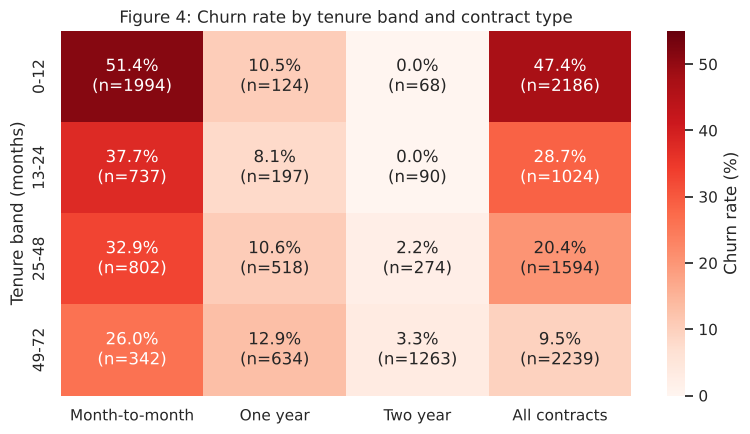

In [13]:
# Figure 4: Is it the contract or the tenure? Churn rate by tenure band within each contract type
tmp = df.assign(tenure_band=pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                                   labels=["0-12", "13-24", "25-48", "49-72"]))
rate_tbl = tmp.pivot_table(index="tenure_band", columns="Contract", values="Churn", aggfunc="mean", margins=True,
                           margins_name="All contracts", observed=False) * 100
n_tbl = tmp.pivot_table(index="tenure_band", columns="Contract", values="Churn", aggfunc="count", margins=True,
                        margins_name="All contracts", observed=False)
rate_tbl = rate_tbl[["Month-to-month", "One year", "Two year", "All contracts"]]
n_tbl = n_tbl[["Month-to-month", "One year", "Two year", "All contracts"]]
labels = rate_tbl.round(1).astype(str) + "%\n(n=" + n_tbl.astype(int).astype(str) + ")"

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(rate_tbl.iloc[:-1], annot=labels.iloc[:-1].values, fmt="", cmap="Reds", vmin=0, vmax=55,
            cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Figure 4: Churn rate by tenure band and contract type")
ax.set_xlabel(""); ax.set_ylabel("Tenure band (months)")
plt.tight_layout()
plt.savefig("figures/fig4_tenure_by_contract.png", dpi=150)
plt.show()

Reading down each column shows the tenure effect within a contract type. For month-to-month customers, churn drops from about 51% in the first year to about 26% after four years, so tenure matters on its own. For one- and two-year contracts churn is low at every tenure (below about 13% and 4%). So part of the overall tenure effect is a composition effect: new customers are mostly on month-to-month plans, which is where churn sits. The highest-risk group is new month-to-month customers.

          mean  median
Churn                 
Stayed   61.27   64.43
Churned  74.44   79.65

Mean monthly charges by internet service and churn status:
Churn            Stayed  Churned
InternetService                 
DSL                60.2     49.1
Fiber optic        93.9     88.1
No                 21.1     20.4


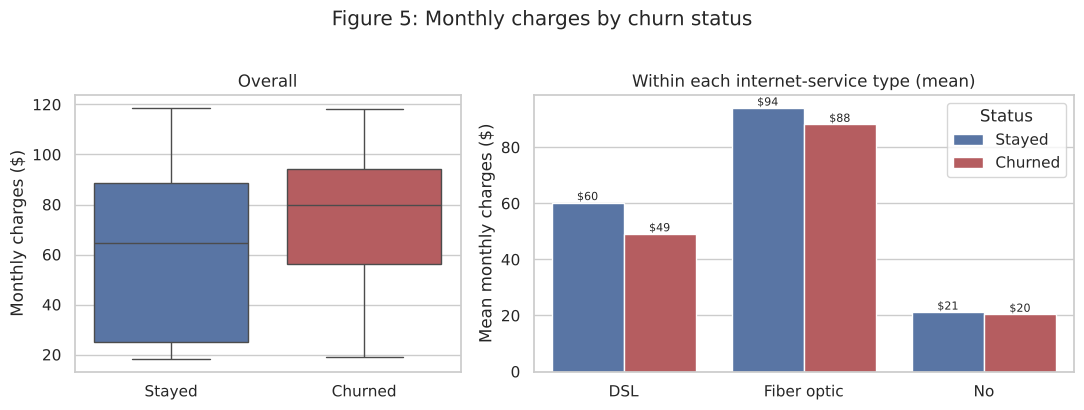

In [14]:
# Figure 5: Monthly charges - overall, and within each internet-service type
status = df["Churn"].map({0: "Stayed", 1: "Churned"})
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.4]})

sns.boxplot(data=df.assign(Status=status), x="Status", y="MonthlyCharges",
            palette=["#4C72B0", "#C44E52"], order=["Stayed", "Churned"], ax=axes[0])
axes[0].set_title("Overall")
axes[0].set_ylabel("Monthly charges ($)"); axes[0].set_xlabel("")

by_net = (df.assign(Status=status).groupby(["InternetService", "Status"])["MonthlyCharges"].mean()
          .reset_index())
sns.barplot(data=by_net, x="InternetService", y="MonthlyCharges", hue="Status",
            hue_order=["Stayed", "Churned"], order=["DSL", "Fiber optic", "No"],
            palette=["#4C72B0", "#C44E52"], ax=axes[1])
for cont in axes[1].containers:
    axes[1].bar_label(cont, fmt="$%.0f", fontsize=8)
axes[1].set_title("Within each internet-service type (mean)")
axes[1].set_ylabel("Mean monthly charges ($)"); axes[1].set_xlabel("")

fig.suptitle("Figure 5: Monthly charges by churn status", y=1.02)
plt.tight_layout()
plt.savefig("figures/fig5_monthly_charges.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).rename(index={0: "Stayed", 1: "Churned"}).round(2))
print()
print("Mean monthly charges by internet service and churn status:")
print(df.groupby(["InternetService", "Churn"])["MonthlyCharges"].mean().round(1).unstack().rename(columns={0: "Stayed", 1: "Churned"}))

Churners pay more per month overall (about \$74 vs \$61), but that doesn't mean price drives churn. Fibre customers pay much more (about \$92 vs \$58 for DSL) and also churn much more. Within the same internet type, churners actually pay slightly less than stayers (DSL: about \$49 vs \$60; fibre: about \$88 vs \$94). This is a mix effect (Simpson's paradox), so the type of service seems to matter more than the bill itself.

Month-to-month customers only (n = 3875):
InternetService
DSL            32.2
Fiber optic    54.6
No             18.9

PaymentMethod
Bank transfer (automatic)    34.1
Credit card (automatic)      32.8
Electronic check             53.7
Mailed check                 31.6


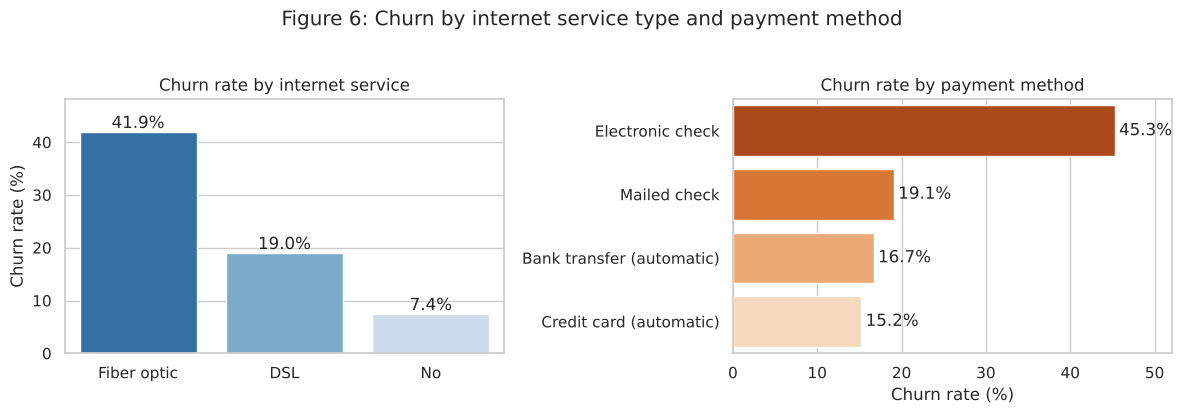

In [15]:
# Figure 6: Churn rate by internet service and by payment method
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

r1 = df.groupby("InternetService")["Churn"].mean().sort_values(ascending=False) * 100
sns.barplot(x=r1.index, y=r1.values, palette="Blues_r", ax=axes[0])
for i, v in enumerate(r1.values):
    axes[0].text(i, v + 0.8, f"{v:.1f}%", ha="center")
axes[0].set_title("Churn rate by internet service")
axes[0].set_ylabel("Churn rate (%)"); axes[0].set_xlabel("")
axes[0].set_ylim(0, r1.max() * 1.15)

r2 = df.groupby("PaymentMethod")["Churn"].mean().sort_values(ascending=False) * 100
sns.barplot(x=r2.values, y=r2.index, palette="Oranges_r", ax=axes[1])
for i, v in enumerate(r2.values):
    axes[1].text(v + 0.5, i, f"{v:.1f}%", va="center")
axes[1].set_title("Churn rate by payment method")
axes[1].set_xlabel("Churn rate (%)"); axes[1].set_ylabel("")
axes[1].set_xlim(0, r2.max() * 1.15)

fig.suptitle("Figure 6: Churn by internet service type and payment method", y=1.03)
plt.tight_layout()
plt.savefig("figures/fig6_service_payment.png", dpi=150, bbox_inches="tight")
plt.show()

# Do these survive once contract type is held fixed? (month-to-month customers only)
m2m = df[df["Contract"] == "Month-to-month"]
print("Month-to-month customers only (n = %d):" % len(m2m))
print((m2m.groupby("InternetService")["Churn"].mean() * 100).round(1).rename("churn % by internet service").to_string())
print()
print((m2m.groupby("PaymentMethod")["Churn"].mean() * 100).round(1).rename("churn % by payment method").to_string())

Fibre-optic customers churn much more than DSL customers or those with no internet, and customers paying by electronic check churn the most while automatic payers churn the least. Both patterns still hold for month-to-month customers only (printed above), so they are not just a contract effect. They are still associations; the data has nothing on fibre pricing, service quality, outages or competitors.

Gender (no meaningful difference):
gender
Female    26.9
Male      26.2


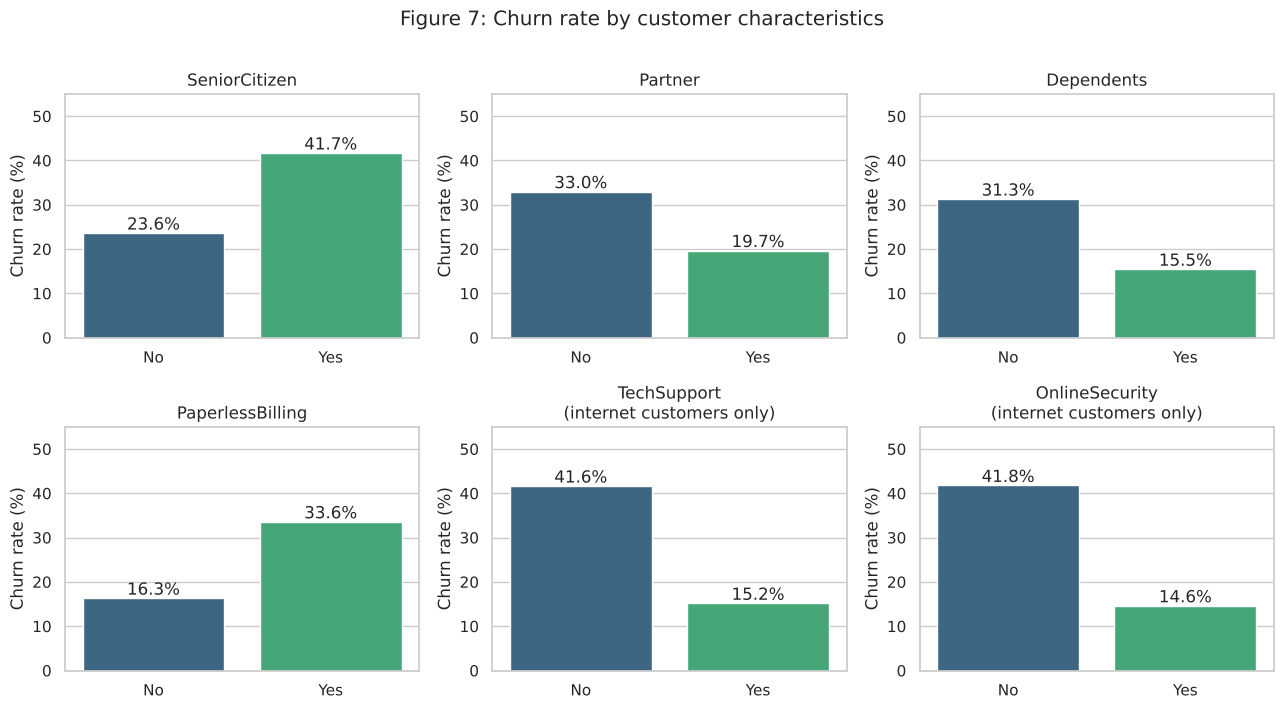

In [16]:
# Figure 7: Churn rate by other customer characteristics
# TechSupport / OnlineSecurity only make sense for customers who HAVE internet, so those two panels
# use internet customers only (otherwise 'No' would mix "chose not to buy" with "could not buy").
internet_only = df[df["InternetService"] != "No"]
panels = [("SeniorCitizen", df, ""), ("Partner", df, ""), ("Dependents", df, ""),
          ("PaperlessBilling", df, ""), ("TechSupport", internet_only, "\n(internet customers only)"),
          ("OnlineSecurity", internet_only, "\n(internet customers only)")]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (col, data, note) in zip(axes.ravel(), panels):
    r = data.groupby(col)["Churn"].mean() * 100
    sns.barplot(x=r.index, y=r.values, palette="viridis", ax=ax)
    for i, v in enumerate(r.values):
        ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
    ax.set_title(col + note); ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("")
    ax.set_ylim(0, 55)
fig.suptitle("Figure 7: Churn rate by customer characteristics", y=1.01)
plt.tight_layout()
plt.savefig("figures/fig7_other_characteristics.png", dpi=150, bbox_inches="tight")
plt.show()

print("Gender (no meaningful difference):")
print((df.groupby("gender")["Churn"].mean() * 100).round(1).to_string())

Senior citizens, customers without a partner or dependents, and paperless-billing users churn more. Among customers with internet, those without tech support or online security churn far more (about 42% vs about 15%). Gender makes almost no difference. These are raw rates and the groups overlap (seniors may be more often on fibre or month-to-month, for example), which is one reason we use a multivariable model later.

Spearman correlation of tenure with churn: -0.37


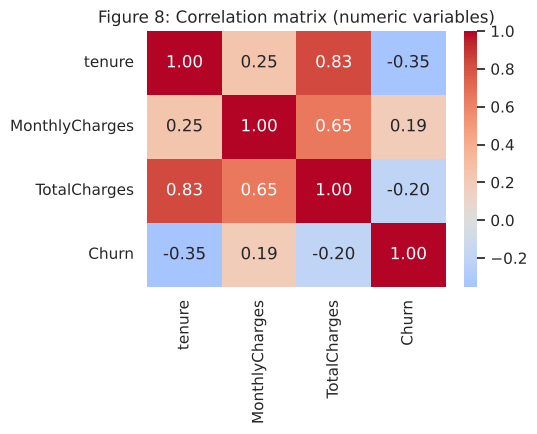

In [17]:
# Figure 8: Correlation between numeric variables and churn
num = df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Figure 8: Correlation matrix (numeric variables)")
plt.tight_layout()
plt.savefig("figures/fig8_correlation.png", dpi=150)
plt.show()
print("Spearman correlation of tenure with churn: %.2f" % stats.spearmanr(df["tenure"], df["Churn"])[0])

`tenure` and `TotalCharges` are strongly correlated because total charges grow with time, so they overlap. Of the numeric variables, `tenure` has the strongest negative relationship with churn: longer tenure, lower churn.

### 3.1 How strong and how reliable are these associations?

In [18]:
# Chi-square test of independence and Cramer's V (effect size, 0 = none, 1 = perfect) for each categorical feature
cat_cols = [c for c in df.columns if c not in ["Churn", "tenure", "MonthlyCharges", "TotalCharges"]]
rows = []
for c in cat_cols:
    ct = pd.crosstab(df[c], df["Churn"])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({"Feature": c, "Cramer's V": round(v, 3), "p-value": "<0.001" if p < 0.001 else f"{p:.3f}"})
assoc = pd.DataFrame(rows).sort_values("Cramer's V", ascending=False).reset_index(drop=True)
print("Table 2: Association of each categorical feature with churn")
print(assoc.to_string())

print()
for c in ["tenure", "MonthlyCharges", "TotalCharges"]:
    a, b = df.loc[df["Churn"] == 1, c], df.loc[df["Churn"] == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    print(f"{c:15s} Mann-Whitney U test p-value: {'<0.001' if p < 0.001 else round(p, 3)}")

Table 2: Association of each categorical feature with churn
             Feature  Cramer's V p-value
0           Contract       0.410  <0.001
1    InternetService       0.322  <0.001
2      PaymentMethod       0.303  <0.001
3   PaperlessBilling       0.191  <0.001
4     OnlineSecurity       0.171  <0.001
5        TechSupport       0.164  <0.001
6         Dependents       0.164  <0.001
7      SeniorCitizen       0.150  <0.001
8            Partner       0.150  <0.001
9       OnlineBackup       0.082  <0.001
10  DeviceProtection       0.066  <0.001
11       StreamingTV       0.063  <0.001
12   StreamingMovies       0.061  <0.001
13     MultipleLines       0.040  <0.001
14      PhoneService       0.011   0.339
15            gender       0.008   0.487

tenure          Mann-Whitney U test p-value: <0.001
MonthlyCharges  Mann-Whitney U test p-value: <0.001
TotalCharges    Mann-Whitney U test p-value: <0.001


With 7,043 customers almost any difference is "significant", so the effect size (Cramer's V) says more than the p-values. Contract type (V about 0.41), internet service (about 0.32) and payment method (about 0.30) are the strongest, while gender and phone service (both about 0.01) are not significant. This gives us a ranking of which variables to take seriously.

### EDA key findings
- About 26.5% churn, so we use recall and F1 alongside accuracy.
- Contract type is the strongest visible driver (Cramer's V about 0.41), with month-to-month customers churning most.
- New customers on month-to-month plans are the highest-risk group, and tenure still matters inside that group.
- Fibre internet and electronic-check payment go with higher churn, even with contract type held fixed. Higher monthly charges don't explain churn on their own (the overall gap is the fibre mix effect).
- Support/security add-ons, partners/dependents and automatic payments go with lower churn.
- Gender and phone service show no meaningful relationship with churn.
- All of this is association. The data can't show that any factor causes churn.

## 4. Feature engineering
We built a few new features from the existing columns. One caveat up front (Section 5.5): they don't improve predictive accuracy, because they mostly rewrite columns the models already see. We kept them because they are easier to explain to a business audience (for example "automatic payer"), and the ablation test shows they do no harm.

| New feature | How it is built | Why |
|---|---|---|
| `tenure_group` | Tenure binned into 0-12, 13-24, 25-48, 49-72 months | Churn drops in steps over a customer's life rather than smoothly, and bands let a linear model pick that up |
| `num_services` | Number of add-ons (security, backup, protection, tech support, streaming TV/movies) | Customers using more services may be less likely to leave |
| `has_protection_services` | 1 if the customer has OnlineSecurity or TechSupport | EDA linked these two with much lower churn |
| `auto_pay` | 1 if payment is automatic (bank transfer or credit card) | Automatic payers churned less in EDA |
| `charge_per_service` | MonthlyCharges divided by (1 + number of services) | Rough measure of what a customer pays for what they get |

In [19]:
df_fe = df.copy()

# Tenure bands
df_fe["tenure_group"] = pd.cut(df_fe["tenure"], bins=[-1, 12, 24, 48, 72],
                               labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)

# Count of add-on services
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df_fe["num_services"] = (df_fe[addon_cols] == "Yes").sum(axis=1)

# Protective services flag
df_fe["has_protection_services"] = ((df_fe["OnlineSecurity"] == "Yes") | (df_fe["TechSupport"] == "Yes")).astype(int)

# Automatic payment flag
df_fe["auto_pay"] = df_fe["PaymentMethod"].str.contains("automatic").astype(int)

# Price relative to number of services
df_fe["charge_per_service"] = df_fe["MonthlyCharges"] / (1 + df_fe["num_services"])

engineered = ["tenure_group", "num_services", "has_protection_services", "auto_pay", "charge_per_service"]
df_fe[["tenure", "tenure_group", "num_services", "has_protection_services", "auto_pay", "charge_per_service"]].head()

   tenure tenure_group  num_services  has_protection_services  auto_pay  \
0       1         0-12             1                        0         0   
1      34        25-48             2                        1         0   
2       2         0-12             2                        1         0   
3      45        25-48             3                        1         1   
4       2         0-12             0                        0         0   

   charge_per_service  
0           14.925000  
1           18.983333  
2           17.950000  
3           10.575000  
4           70.700000  

In [20]:
# Quick sanity check: do the new features relate to churn the way we expected?
print((df_fe.groupby("tenure_group")["Churn"].mean() * 100).round(1).rename("churn % by tenure_group"), "\n")
print((df_fe.groupby("auto_pay")["Churn"].mean() * 100).round(1).rename("churn % by auto_pay"), "\n")

# num_services: the 0-services group mixes 'no internet at all' (low churn) with 'internet but no add-ons' (high churn)
has_net = df_fe["InternetService"] != "No"
print((df_fe[has_net].groupby("num_services")["Churn"].mean() * 100).round(1)
      .rename("churn % by num_services (internet customers only)"))
print("\nNo-internet customers: churn = %.1f%%" % (df_fe[~has_net]["Churn"].mean() * 100))

tenure_group
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: churn % by tenure_group, dtype: float64 

auto_pay
0    34.7
1    16.0
Name: churn % by auto_pay, dtype: float64 

num_services
0    52.2
1    45.8
2    35.8
3    27.4
4    22.3
5    12.4
6     5.3
Name: churn % by num_services (internet customers only), dtype: float64

No-internet customers: churn = 7.4%


As expected, churn falls as tenure grows and as customers hold more add-on services (customers with no internet are shown separately because they are a low-churn group that would blur the first bar), and automatic payers churn far less than manual payers.

## 5. Model training and comparison

### 5.1 Train/test split and preprocessing
- **Split:** 80% train / 20% test, stratified so both keep the ~26.5% churn rate. The test set is not used for tuning or model selection, only for the final evaluation. Tuning and selection use cross-validation inside the training set.
- **Preprocessing** is inside a scikit-learn `Pipeline`, so it is fitted on training data only (no leakage). Numeric columns are standardised and categorical columns are one-hot encoded.
- **No target leakage:** no input is derived from `Churn`, and `customerID` is removed.

In [21]:
X = df_fe.drop(columns="Churn")
y = df_fe["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " churn rate:", round(y_train.mean(), 3))
print("Test: ", X_test.shape,  " churn rate:", round(y_test.mean(), 3))

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges", "num_services", "charge_per_service"]
categorical_features = [c for c in X.columns if c not in numeric_features]
print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), categorical_features),
])

Train: (5634, 24)  churn rate: 0.265
Test:  (1409, 24)  churn rate: 0.265

Numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges', 'num_services', 'charge_per_service']
Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group', 'has_protection_services', 'auto_pay']


### 5.2 Models chosen
| Model | Why |
|---|---|
| **Baseline (always predict "stays")** | The minimum any useful model has to beat. About 73% accuracy, catches no churners. |
| **Logistic Regression** | Simple, fast and interpretable; the coefficients show the direction and size of each effect. |
| **Random Forest** | Many decision trees, so it can pick up non-linear patterns and interactions (e.g. tenure with contract type) without manual work. |

Both models use `class_weight="balanced"` so they don't just ignore the churners, and both are tuned with a grid search (5-fold stratified CV on F1, training data only) so neither gets an unfair advantage. We widened the grids after the first attempt because the best values were sitting at the edge.

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# --- Baseline ---
baseline = Pipeline([("prep", preprocessor), ("model", DummyClassifier(strategy="most_frequent"))])
baseline.fit(X_train, y_train)

# --- Model 1: Logistic Regression, tuned over the regularisation strength C (smaller C = stronger regularisation) ---
C_values = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]
log_reg_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)),
])
lr_grid = GridSearchCV(log_reg_pipe, {"model__C": C_values}, cv=cv, scoring="f1", n_jobs=-1)
lr_grid.fit(X_train, y_train)
log_reg = lr_grid.best_estimator_
print("Logistic Regression: best parameters:", lr_grid.best_params_)
print(f"Logistic Regression: 5-fold CV F1 (train) = {lr_grid.best_score_:.3f}")
print("CV F1 for each C:", {c: round(float(v), 3) for c, v in zip(C_values, lr_grid.cv_results_["mean_test_score"])})

Logistic Regression: best parameters: {'model__C': 0.003}
Logistic Regression: 5-fold CV F1 (train) = 0.635
CV F1 for each C: {0.001: 0.629, 0.003: 0.635, 0.01: 0.634, 0.03: 0.628, 0.1: 0.627, 0.3: 0.627, 1: 0.625, 3: 0.628}


In [23]:
# --- Model 2: Random Forest with a grid search ---
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
])
param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [6, 10, None],
    "model__min_samples_leaf": [3, 8, 16, 32],
}
rf_grid = GridSearchCV(rf_pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)
rf_grid.fit(X_train, y_train)

rand_forest = rf_grid.best_estimator_
print("Best Random Forest parameters:", rf_grid.best_params_)
print(f"Random Forest: 5-fold CV F1 (train) = {rf_grid.best_score_:.3f}")

top = (pd.DataFrame(rf_grid.cv_results_)
       [["param_model__n_estimators", "param_model__max_depth", "param_model__min_samples_leaf", "mean_test_score"]]
       .sort_values("mean_test_score", ascending=False).head(5).round(3))
top.columns = ["n_estimators", "max_depth", "min_samples_leaf", "CV F1"]
print("\nTop 5 settings (the scores are all very close, so the exact choice matters little):")
print(top.to_string(index=False))

Best Random Forest parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}
Random Forest: 5-fold CV F1 (train) = 0.635

Top 5 settings (the scores are all very close, so the exact choice matters little):
 n_estimators max_depth  min_samples_leaf  CV F1
          400        10                 3  0.635
          200        10                 3  0.633
          400      None                32  0.633
          400      None                16  0.633
          400        10                32  0.633


### 5.3 Is the difference between the two models real?
One cross-validation score can't tell us whether a gap of 0.002 is real or noise. So we compare the two tuned models with repeated 5-fold cross-validation (3 repeats, 15 scores per model) on the training data and look at the average and the spread.

In [24]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
scoring = {"F1": "f1", "Recall": "recall", "Precision": "precision", "ROC-AUC": "roc_auc", "Accuracy": "accuracy"}

tuned = {"Logistic Regression (tuned)": log_reg, "Random Forest (tuned)": rand_forest}
cvres = {name: cross_validate(clone(m), X_train, y_train, cv=rcv, scoring=scoring, n_jobs=-1)
         for name, m in tuned.items()}

rows = []
for name, r in cvres.items():
    rows.append({"Model": name, **{k: f"{r['test_'+k].mean():.3f} +/- {r['test_'+k].std():.3f}" for k in scoring}})
print("Repeated 5-fold CV on the training set (mean +/- standard deviation across 15 folds)")
pd.DataFrame(rows).set_index("Model")

Repeated 5-fold CV on the training set (mean +/- standard deviation across 15 folds)


                                          F1           Recall  \
Model                                                           
Logistic Regression (tuned)  0.635 +/- 0.016  0.775 +/- 0.029   
Random Forest (tuned)        0.635 +/- 0.015  0.767 +/- 0.028   

                                   Precision          ROC-AUC         Accuracy  
Model                                                                           
Logistic Regression (tuned)  0.538 +/- 0.015  0.842 +/- 0.012  0.764 +/- 0.010  
Random Forest (tuned)        0.543 +/- 0.019  0.846 +/- 0.012  0.766 +/- 0.013  

In [25]:
lr_f1 = cvres["Logistic Regression (tuned)"]["test_F1"]
rf_f1 = cvres["Random Forest (tuned)"]["test_F1"]
diff = rf_f1 - lr_f1
print("Random Forest minus Logistic Regression, F1: mean difference = %+.4f" % diff.mean())
print("Fold-to-fold standard deviation of F1: LR = %.4f, RF = %.4f" % (lr_f1.std(), rf_f1.std()))
print("Share of the 15 folds where Random Forest scores higher: %.0f%%" % ((diff > 0).mean() * 100))

# Selection rule (written down before the test set was looked at): choose the model with the higher mean CV F1, UNLESS the gap is smaller than the
# fold-to-fold noise, in which case treat the models as tied and prefer the simpler, more interpretable one.
noise = max(lr_f1.std(), rf_f1.std())
if abs(diff.mean()) < noise:
    best_name = "Logistic Regression (tuned)"
    print("\nGap (%.4f) is smaller than the fold-to-fold noise (%.4f): the models are tied." % (abs(diff.mean()), noise))
    print("Selected on the tie-break (simpler and interpretable):", best_name)
else:
    best_name = max(cvres, key=lambda k: cvres[k]["test_F1"].mean())
    print("\nSelected on higher mean CV F1:", best_name)
best_model = tuned[best_name]

Random Forest minus Logistic Regression, F1: mean difference = +0.0001
Fold-to-fold standard deviation of F1: LR = 0.0156, RF = 0.0145
Share of the 15 folds where Random Forest scores higher: 33%

Gap (0.0001) is smaller than the fold-to-fold noise (0.0156): the models are tied.
Selected on the tie-break (simpler and interpretable): Logistic Regression (tuned)


**Result.** The two tuned models are tied. Mean cross-validated F1 is 0.635 for both, the Random Forest wins in only 5 of the 15 folds (33%), and the gap (0.0001) is about 100 times smaller than the fold-to-fold spread (about 0.015). ROC-AUC, recall and precision are within noise too. So we applied a tie-break rule we set before looking at the test set, and chose Logistic Regression: same performance, simpler, and its coefficients can be explained directly. The Random Forest is saved alongside it.

Why not just take the higher number? Our first comparison tuned only the Random Forest and left Logistic Regression on defaults, which made the Random Forest look slightly better (F1 0.635 vs 0.625). That gap disappears once both are tuned, so saying the Random Forest is better wouldn't hold up.

### 5.4 Comparison on the held-out test set
The test set wasn't used for tuning or for choosing the model. It is used here only to report how each model does on customers it hasn't seen.

In [26]:
def evaluate(name, model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }

results = pd.DataFrame([
    evaluate("Baseline (always 'stays')", baseline),
    evaluate("Logistic Regression (tuned)", log_reg),
    evaluate("Random Forest (tuned)", rand_forest),
]).set_index("Model").round(3)
results

                             Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                                      
Baseline (always 'stays')       0.735      0.000   0.000     0.000    0.500
Logistic Regression (tuned)     0.749      0.519   0.775     0.622    0.837
Random Forest (tuned)           0.760      0.533   0.767     0.629    0.842

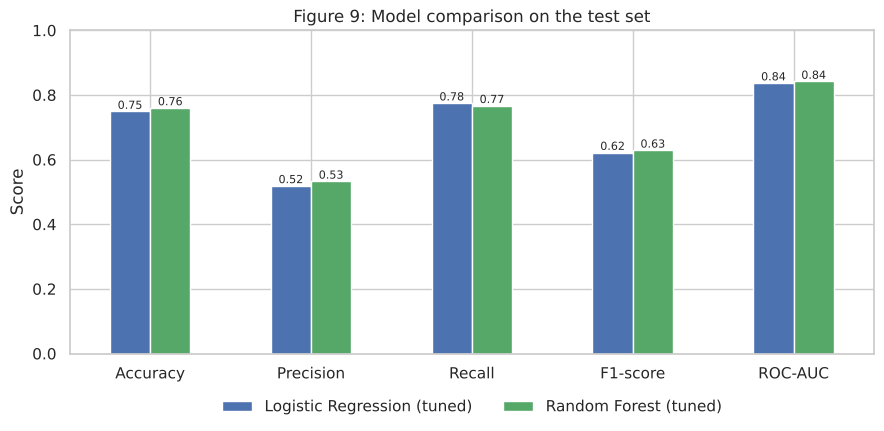

In [27]:
# Figure 9: bar chart of the comparison (the two real models)
ax = results.loc[["Logistic Regression (tuned)", "Random Forest (tuned)"]].T.plot(
    kind="bar", figsize=(9, 4.5), color=["#4C72B0", "#55A868"], rot=0)
ax.set_title("Figure 9: Model comparison on the test set")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, title=None, frameon=False)
plt.tight_layout()
plt.savefig("figures/fig9_model_comparison.png", dpi=150)
plt.show()

On the 1,409 test customers (374 real churners) the Random Forest is marginally higher (F1 0.629 vs 0.622, ROC-AUC 0.842 vs 0.837), while Logistic Regression catches slightly more churners (recall 0.775 vs 0.767). Gaps this small are within sampling noise for one test set, and we didn't use the test set to choose, so we don't switch to the Random Forest. Both beat the baseline clearly: they catch about three out of four churners, and the baseline catches none.

*Precision* is how many of the customers we flagged really churned. *Recall* is how many of the real churners we caught. For a retention team recall matters a lot (a missed churner is lost revenue), but precision matters too because every false alarm is a wasted offer. F1 balances the two, and ROC-AUC measures how well the model ranks churners above non-churners across all thresholds. Confusion matrices, drivers, thresholds and fairness are in Section 7.

### 5.5 Do the engineered features actually help?
To check, we re-run the repeated cross-validation with only the original columns and compare.

In [28]:
def make_pipe(cols, model):
    num = [c for c in numeric_features if c in cols]
    cat = [c for c in cols if c not in num]
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat)])
    return Pipeline([("prep", pre), ("model", clone(model))])

original_cols = [c for c in X.columns if c not in engineered]
rows = []
for name, est in tuned.items():
    base_cv = cross_validate(make_pipe(original_cols, est.named_steps["model"]), X_train[original_cols], y_train,
                             cv=rcv, scoring=scoring, n_jobs=-1)
    for label, r in [("original columns only", base_cv), ("original + engineered", cvres[name])]:
        rows.append({"Model": name, "Features": label,
                     "F1": round(r["test_F1"].mean(), 3), "ROC-AUC": round(r["test_ROC-AUC"].mean(), 3),
                     "Recall": round(r["test_Recall"].mean(), 3), "Precision": round(r["test_Precision"].mean(), 3)})
pd.DataFrame(rows).set_index(["Model", "Features"])

                                                      F1  ROC-AUC  Recall  \
Model                       Features                                        
Logistic Regression (tuned) original columns only  0.632    0.841   0.786   
                            original + engineered  0.635    0.842   0.775   
Random Forest (tuned)       original columns only  0.637    0.847   0.773   
                            original + engineered  0.635    0.846   0.767   

                                                   Precision  
Model                       Features                          
Logistic Regression (tuned) original columns only      0.528  
                            original + engineered      0.538  
Random Forest (tuned)       original columns only      0.542  
                            original + engineered      0.543  

The engineered features make no meaningful difference to performance (F1 changes of about 0.00 to 0.01, well inside the fold-to-fold noise). That makes sense: `tenure_group`, `auto_pay` and `has_protection_services` just re-express columns the models already have, and `num_services` is a sum of existing columns. So they are justified by interpretability, not accuracy, and we say so in the report instead of claiming they improved the model.

## 6. Save the final model

In [29]:
# Final model = the one chosen in Section 5.3 using TRAINING-set cross-validation only (never the test set).
print("Final model:", best_name)
joblib.dump(best_model, "models/best_churn_model.joblib")
# Also save the other tuned model so the comparison can be reproduced and the alternative can be used if the team prefers it
other_name = [k for k in tuned if k != best_name][0]
other_file = "models/random_forest_model.joblib" if other_name.startswith("Random") else "models/logistic_regression_model.joblib"
joblib.dump(tuned[other_name], other_file)

metadata = {
    "final_model": best_name,
    "final_model_hyperparameters": {k: v for k, v in best_model.named_steps["model"].get_params().items()
                                    if k in ("C", "class_weight", "max_iter", "n_estimators", "max_depth", "min_samples_leaf")},
    "other_saved_model": {"name": other_name, "file": other_file},
    "input_columns": list(X.columns),
    "target": "Churn (1 = churned)",
    "random_state": RANDOM_STATE,
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
    "test_set_results": results.loc[["Logistic Regression (tuned)", "Random Forest (tuned)"]].to_dict(orient="index"),
}
with open("models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)
print("Saved models/best_churn_model.joblib, %s and models/model_metadata.json" % other_file)

Final model: Logistic Regression (tuned)
Saved models/best_churn_model.joblib, models/random_forest_model.joblib and models/model_metadata.json


In [30]:
# Reload the saved model and test it on a made-up customer
loaded = joblib.load("models/best_churn_model.joblib")

new_customer = pd.DataFrame([{
    "gender": "Female", "SeniorCitizen": "No", "Partner": "No", "Dependents": "No",
    "tenure": 3, "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Month-to-month",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 95.0, "TotalCharges": 285.0,
    # engineered features (same formulas as in Section 4)
    "tenure_group": "0-12", "num_services": 2, "has_protection_services": 0,
    "auto_pay": 0, "charge_per_service": 95.0 / 3,
}])[X.columns]

prob = loaded.predict_proba(new_customer)[0, 1]
print(f"Predicted churn score: {prob:.1%}  (a risk score for ranking; class weights make it run higher than a true probability)")
print("Prediction:", "WILL CHURN" if loaded.predict(new_customer)[0] == 1 else "will stay")

# Sanity check: the reloaded model gives exactly the same test-set predictions as the in-memory model
assert (loaded.predict(X_test) == best_model.predict(X_test)).all()
print("Reloaded model reproduces the in-memory predictions exactly.")

Predicted churn score: 87.4%  (a risk score for ranking; class weights make it run higher than a true probability)
Prediction: WILL CHURN
Reloaded model reproduces the in-memory predictions exactly.


## 7. Results and evaluation
This section re-runs the evaluation on our final models and the exact test rows from Section 5, so the numbers match the rest of the notebook and the report.

The question isn't only how accurate the model is, but whether a retention team can act on it. So we look at the kinds of errors it makes, what it relies on, how the flagging threshold changes the workload, and whether it treats customer groups differently.

### 7.1 Errors: confusion matrices

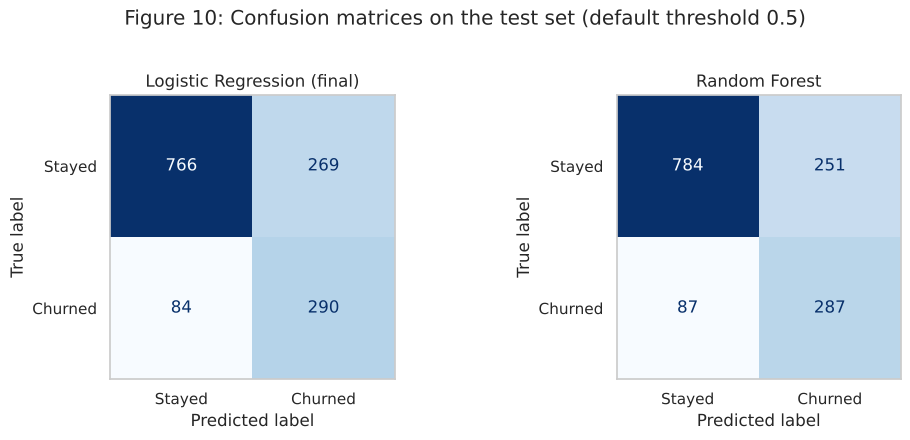

                              TN   FP  FN   TP  Churners caught (%)  \
Model                                                                 
Logistic Regression (final)  766  269  84  290                 77.5   
Random Forest                784  251  87  287                 76.7   

                             Flags that are false alarms (%)  \
Model                                                          
Logistic Regression (final)                             48.1   
Random Forest                                           46.7   

                             Customers flagged (%)  
Model                                               
Logistic Regression (final)                   39.7  
Random Forest                                 38.2  

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

eval_models = {"Logistic Regression (final)": log_reg, "Random Forest": rand_forest}
os.makedirs("evaluation_data", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
cm_rows = []
for ax, (name, m) in zip(axes, eval_models.items()):
    pred = m.predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    cm_rows.append({"Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                    "Churners caught (%)": round(tp / (tp + fn) * 100, 1),
                    "Flags that are false alarms (%)": round(fp / (tp + fp) * 100, 1),
                    "Customers flagged (%)": round((tp + fp) / len(y_test) * 100, 1)})
    ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
fig.suptitle("Figure 10: Confusion matrices on the test set (default threshold 0.5)", y=1.02)
plt.tight_layout()
plt.savefig("figures/fig10_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

cm_table = pd.DataFrame(cm_rows).set_index("Model")
cm_table.to_csv("evaluation_data/confusion_counts.csv")
cm_table

At the default threshold the final model finds about three out of four churners, but a little over 48% of the customers it flags are false alarms, meaning people who would have stayed anyway and still get an offer. For a business that can't contact everyone this is the main weakness, and Section 7.3 shows how the threshold can help.

### 7.2 What drives the predictions?
Permutation importance shuffles one column at a time on the test set and measures how much F1 drops; a bigger drop means the model relies on that column more. It describes what the model uses, not what causes churn. Correlated columns share importance (tenure, `tenure_group` and `TotalCharges` overlap), so we treat the ranking as a guide, not exact weights.

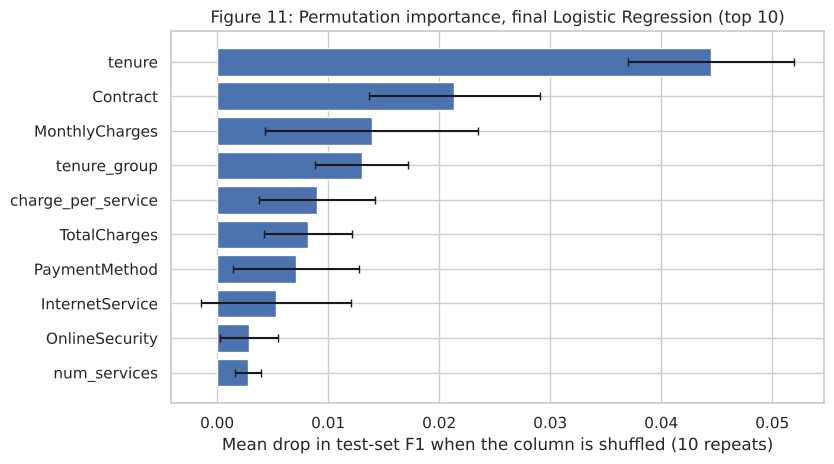

              Feature  Mean F1 drop  Std. dev.
0              tenure        0.0445     0.0075
1            Contract        0.0214     0.0077
2      MonthlyCharges        0.0139     0.0096
3        tenure_group        0.0130     0.0042
4  charge_per_service        0.0090     0.0052
5        TotalCharges        0.0082     0.0040
6       PaymentMethod        0.0071     0.0057
7     InternetService        0.0053     0.0067
8      OnlineSecurity        0.0029     0.0026
9        num_services        0.0028     0.0012

In [32]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(log_reg, X_test, y_test, scoring="f1", n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
importance = (pd.DataFrame({"Feature": X_test.columns, "Mean F1 drop": imp.importances_mean, "Std. dev.": imp.importances_std})
              .sort_values("Mean F1 drop", ascending=False).reset_index(drop=True))
importance.to_csv("evaluation_data/permutation_importance.csv", index=False)

top = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(top["Feature"], top["Mean F1 drop"], xerr=top["Std. dev."], color="#4C72B0", capsize=3)
ax.set_xlabel("Mean drop in test-set F1 when the column is shuffled (10 repeats)")
ax.set_title("Figure 11: Permutation importance, final Logistic Regression (top 10)")
plt.tight_layout()
plt.savefig("figures/fig11_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

importance.head(10).round(4)

In [33]:
# Direction of the effects: coefficients of the final Logistic Regression (after scaling / one-hot encoding)
names = log_reg.named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({"Feature": names, "Coefficient": log_reg.named_steps["model"].coef_.ravel()})
coefs.to_csv("evaluation_data/logistic_coefficients.csv", index=False)
print("Largest positive coefficients (push the score towards churn):")
print(coefs.nlargest(6, "Coefficient").round(3).to_string(index=False))
print("\nLargest negative coefficients (push the score towards staying):")
print(coefs.nsmallest(6, "Coefficient").round(3).to_string(index=False))

Largest positive coefficients (push the score towards churn):
                            Feature  Coefficient
       cat__Contract_Month-to-month        0.370
                num__MonthlyCharges        0.343
   cat__InternetService_Fiber optic        0.243
cat__PaymentMethod_Electronic check        0.220
          cat__PaperlessBilling_Yes        0.211
             cat__tenure_group_0-12        0.207

Largest negative coefficients (push the score towards staying):
                       Feature  Coefficient
                   num__tenure       -0.395
        cat__Contract_Two year       -0.269
       cat__InternetService_No       -0.204
cat__has_protection_services_1       -0.137
             num__TotalCharges       -0.136
           cat__Dependents_Yes       -0.132


Tenure is by far the most important input, then contract type, followed by monthly charges, tenure band, payment method and internet service. The coefficients agree with the EDA: short tenure, month-to-month contracts, fibre, electronic check and higher monthly charges push the score towards churn, while long tenure, two-year contracts, no internet service, security or tech support, and having dependents push it towards staying. Two cautions: the strong L2 penalty (C = 0.003) shrinks coefficients and correlated columns split the credit, and the positive `MonthlyCharges` coefficient depends on the other columns, so it shouldn't be read as "higher prices cause churn" (Section 3 showed the raw price gap is a fibre mix effect).

### 7.3 Choosing the threshold: workload and economics
The model gives each customer a churn score, and 0.5 is only a default cut-off. Lowering it catches more churners but flags more people; raising it does the opposite.

Average model score: 43.3%  vs  actual churn rate in the test set: 26.5%  (class weights inflate the scores, so use them to rank, not as probabilities)



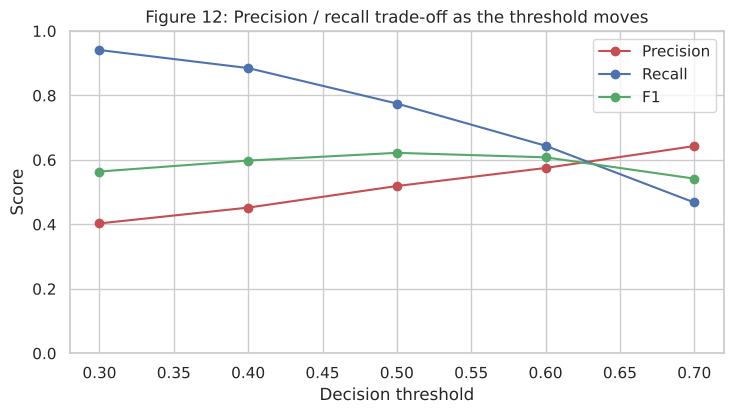

   Threshold  Customers flagged  Flagged (%)  Precision  Recall     F1  \
0        0.3                874         62.0      0.403   0.941  0.564   
1        0.4                733         52.0      0.452   0.885  0.598   
2        0.5                559         39.7      0.519   0.775  0.622   
3        0.6                419         29.7      0.575   0.644  0.608   
4        0.7                272         19.3      0.643   0.468  0.542   

   True churners found  False alarms  
0                  352           522  
1                  331           402  
2                  290           269  
3                  241           178  
4                  175            97  

In [34]:
proba = log_reg.predict_proba(X_test)[:, 1]
print("Average model score: %.1f%%  vs  actual churn rate in the test set: %.1f%%  (class weights inflate the scores, so use them to rank, not as probabilities)\n" % (proba.mean() * 100, y_test.mean() * 100))
rows = []
for th in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba >= th).astype(int)
    rows.append({"Threshold": th, "Customers flagged": int(p.sum()), "Flagged (%)": round(p.mean() * 100, 1),
                 "Precision": round(precision_score(y_test, p), 3), "Recall": round(recall_score(y_test, p), 3),
                 "F1": round(f1_score(y_test, p), 3), "True churners found": int(((p == 1) & (y_test == 1)).sum()),
                 "False alarms": int(((p == 1) & (y_test == 0)).sum())})
thr = pd.DataFrame(rows)
thr.to_csv("evaluation_data/threshold_sensitivity.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.3))
for col, colr in [("Precision", "#C44E52"), ("Recall", "#4C72B0"), ("F1", "#55A868")]:
    ax.plot(thr["Threshold"], thr[col], marker="o", label=col, color=colr)
ax.set_ylim(0, 1); ax.set_xlabel("Decision threshold"); ax.set_ylabel("Score"); ax.legend()
ax.set_title("Figure 12: Precision / recall trade-off as the threshold moves")
plt.tight_layout()
plt.savefig("figures/fig12_threshold_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()
thr

**Economics (illustrative assumptions, not company data).** Whether contacting a flagged customer pays off depends on three numbers the dataset doesn't have: the cost of an offer, the chance it works, and the value of a saved customer. A group of flagged customers is worth contacting when precision x success rate x value > cost, so the break-even precision is cost / (success rate x value). The cell below sets the assumptions out so they are easy to change; they should be replaced with the retention team's real numbers.

*Note on scores:* because of the balanced class weights, the scores run higher than true probabilities (average score about 43% when only 26.5% churn). They are good for ranking customers by risk but shouldn't be read as literal probabilities, and the economics below use the observed precision, not the score.

In [35]:
# ---- ILLUSTRATIVE ASSUMPTIONS (change these to the company's real figures) ----
COST_PER_OFFER = 20        # $ per customer contacted (call time + offer)
SUCCESS_RATE   = 0.30      # share of genuine churners an offer would keep
MARGIN         = 0.30      # profit margin on revenue
MONTHS_KEPT    = 12        # months of margin a saved customer is assumed to generate
avg_churner_bill = df.loc[df["Churn"] == 1, "MonthlyCharges"].mean()
VALUE = avg_churner_bill * MONTHS_KEPT * MARGIN
print(f"Average monthly bill of a churner: ${avg_churner_bill:.2f}  ->  assumed value of a saved customer: ${VALUE:.0f}")

thr["Net benefit ($)"] = (thr["True churners found"] * SUCCESS_RATE * VALUE - thr["Customers flagged"] * COST_PER_OFFER).round(0).astype(int)
thr.to_csv("evaluation_data/threshold_sensitivity.csv", index=False)
print("\nIllustrative net benefit on the 1,409 test customers (do-nothing = $0):")
print(thr[["Threshold", "Customers flagged", "True churners found", "False alarms", "Net benefit ($)"]].to_string(index=False))

# Break-even precision for different cost / success-rate scenarios (value fixed as above)
be = pd.DataFrame([{"Cost per offer ($)": c, **{f"success rate {int(sr*100)}%": round(c / (sr * VALUE), 2) for sr in [0.2, 0.3, 0.5]}}
                   for c in [10, 20, 40]])
print("\nBreak-even precision (share of flagged customers who must really churn for contacting them to pay off):")
print(be.to_string(index=False))
print("\nObserved precision of the final model: %.2f at threshold 0.5, %.2f at 0.6" % (thr.loc[thr.Threshold == 0.5, "Precision"].iloc[0], thr.loc[thr.Threshold == 0.6, "Precision"].iloc[0]))

Average monthly bill of a churner: $74.44  ->  assumed value of a saved customer: $268

Illustrative net benefit on the 1,409 test customers (do-nothing = $0):
 Threshold  Customers flagged  True churners found  False alarms  Net benefit ($)
       0.3                874                  352           522            10820
       0.4                733                  331           402            11951
       0.5                559                  290           269            12135
       0.6                419                  241           178            10996
       0.7                272                  175            97             8629

Break-even precision (share of flagged customers who must really churn for contacting them to pay off):
 Cost per offer ($)  success rate 20%  success rate 30%  success rate 50%
                 10              0.19              0.12              0.07
                 20              0.37              0.25              0.15
                 40  

### 7.4 Does the model treat groups differently?
This is a quick diagnostic, not a full fairness audit. For each group we compare the observed churn rate, the share flagged, recall, and the false-alarm rate (the share of customers who stayed but were flagged). A group that is flagged more often gets more offers, and whether that is a problem depends on whether offers are a benefit or a burden.

In [36]:
pred_final = log_reg.predict(X_test)
rows = []
for col in ["SeniorCitizen", "gender"]:
    for val in sorted(X_test[col].unique()):
        mk = (X_test[col] == val).to_numpy()
        yt, yp, pr = y_test.to_numpy()[mk], pred_final[mk], proba[mk]
        rows.append({"Attribute": col, "Group": val, "N": int(mk.sum()),
                     "Observed churn (%)": round(yt.mean() * 100, 1), "Mean predicted score (%)": round(pr.mean() * 100, 1),
                     "Flagged (%)": round(yp.mean() * 100, 1), "Precision": round(precision_score(yt, yp), 3),
                     "Recall": round(recall_score(yt, yp), 3),
                     "False-alarm rate (%)": round(((yp == 1) & (yt == 0)).sum() / (yt == 0).sum() * 100, 1)})
fair = pd.DataFrame(rows)
fair.to_csv("evaluation_data/fairness_check.csv", index=False)
fair

       Attribute   Group     N  Observed churn (%)  Mean predicted score (%)  \
0  SeniorCitizen      No  1187                23.3                      40.6   
1  SeniorCitizen     Yes   222                44.1                      57.5   
2         gender  Female   687                28.1                      43.6   
3         gender    Male   722                25.1                      43.0   

   Flagged (%)  Precision  Recall  False-alarm rate (%)  
0         35.2      0.490   0.743                  23.4  
1         63.5      0.603   0.867                  45.2  
2         40.5      0.536   0.772                  26.1  
3         38.9      0.502   0.779                  25.9  

In [37]:
# Sensitivity: does dropping SeniorCitizen and gender from the inputs change anything?
drop_cols = ["SeniorCitizen", "gender"]
keep = [c for c in X.columns if c not in drop_cols]
no_prot = make_pipe(keep, log_reg.named_steps["model"]).fit(X_train[keep], y_train)
pp = no_prot.predict_proba(X_test[keep])[:, 1]
pr_ = (pp >= 0.5).astype(int)
sen = (X_test["SeniorCitizen"] == "Yes").to_numpy()
print("Without SeniorCitizen and gender as inputs:")
print("  F1 = %.3f (final model %.3f), ROC-AUC = %.3f (final model %.3f)" % (f1_score(y_test, pr_), f1_score(y_test, pred_final), roc_auc_score(y_test, pp), roc_auc_score(y_test, proba)))
print("  Seniors flagged: %.1f%% (final model %.1f%%); non-seniors flagged: %.1f%% (final model %.1f%%)" % (pr_[sen].mean() * 100, pred_final[sen].mean() * 100, pr_[~sen].mean() * 100, pred_final[~sen].mean() * 100))

Without SeniorCitizen and gender as inputs:
  F1 = 0.619 (final model 0.622), ROC-AUC = 0.836 (final model 0.837)
  Seniors flagged: 61.3% (final model 63.5%); non-seniors flagged: 35.7% (final model 35.2%)


Gender is treated almost identically (flagged 40.5% vs 38.9%, false-alarm rates 26.1% vs 25.9%). Senior citizens are flagged far more often (63.5% vs 35.2%), and almost half of the seniors who stayed were still flagged (45.2% vs 23.4%). Part of this is real: seniors churn much more in the data (44.1% vs 23.3%), so the model catches more of their churners (recall 0.87 vs 0.74) and its flags are right more often (precision 0.60 vs 0.49). Even so, seniors would get nearly twice as many offers, including unnecessary ones. The sensitivity check above shows that dropping age and gender as inputs costs almost nothing (F1 0.619 vs 0.622) but doesn't close the gap (seniors still flagged 61.3% vs 35.7%), because it comes from correlated factors like contract and service type. If offers are a benefit this may be fine; if they involve price changes or pressure it needs review. There are only 222 seniors in the test set, so these rates are uncertain.

### 7.5 One held-out customer
One case shows the workflow, not how reliable the model is (the test-set metrics do that). This is a real customer from the held-out test set, and their outcome wasn't used in training.

In [38]:
# A held-out customer (tenure 17, month-to-month, DSL, electronic check, $45.05/month)
mask = ((X_test["tenure"] == 17) & (X_test["MonthlyCharges"] == 45.05) & (X_test["Contract"] == "Month-to-month")).to_numpy()
assert mask.sum() == 1
example = X_test[mask]
score = log_reg.predict_proba(example)[0, 1]
os.makedirs("demo", exist_ok=True)
example.to_csv("demo/demo_customer_test_case.csv", index=False)

print("Customer profile:")
print(example[["tenure", "Contract", "InternetService", "PaymentMethod", "TechSupport", "MonthlyCharges", "SeniorCitizen"]].T.to_string(header=False))
print(f"\nModel churn score: {score:.1%}  ->  prediction: {'WILL CHURN' if score >= 0.5 else 'will stay'}")
print("Recorded outcome:  ", "churned" if y_test[mask].iloc[0] == 1 else "stayed")

Customer profile:
tenure                         17
Contract           Month-to-month
InternetService               DSL
PaymentMethod    Electronic check
TechSupport                    No
MonthlyCharges              45.05
SeniorCitizen                 Yes

Model churn score: 64.0%  ->  prediction: WILL CHURN
Recorded outcome:   churned


In [39]:
# Save the evaluation tables for the report (CSV copies of what is printed above)
results.to_csv("evaluation_data/model_metrics.csv")
print("Saved:", ", ".join(sorted(os.listdir("evaluation_data"))))

Saved: confusion_counts.csv, fairness_check.csv, logistic_coefficients.csv, model_metrics.csv, permutation_importance.csv, threshold_sensitivity.csv


## Summary
- Cleaned the data (fixed `TotalCharges`, standardised categories, no duplicate customers or outliers) and checked the columns are consistent.
- Churn is linked to contract type, early tenure on month-to-month plans, fibre internet, electronic-check payment and lacking support/security services. Higher monthly charges don't explain churn on their own (the gap is a fibre mix effect).
- Built five engineered features (kept for interpretability, no accuracy gain), trained a baseline and two tuned classifiers, and showed with repeated cross-validation that the two perform about the same. We picked the tuned Logistic Regression as the simpler, interpretable one.
- On the held-out test set the final model finds about 77% of churners (recall 0.775, precision 0.519, F1 0.622, ROC-AUC 0.837), but about 48% of its flags are false alarms at the default threshold. The threshold can be set to the retention team's capacity and costs.
- Tenure and contract type matter most. Seniors are flagged about twice as often as non-seniors; gender is treated almost identically.
- Recommendation: use the model as a risk-ranking tool in a controlled pilot, with a random comparison group to measure whether offers really retain customers, not as an automatic decision system.
- The full pipeline is saved in `models/best_churn_model.joblib` (with the other tuned model and a metadata file). Tables and figures for the report are in `evaluation_data/` and `figures/`.

All associations here are correlations; they don't prove that any single factor makes customers leave.